In [3]:

# Cell 1: Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler



In [4]:
# Cell 2: Load dataset

iris = load_iris(as_frame=True)
X = iris.data

print("Dataset shape:", X.shape)
display(X.head())
print("\nOriginal feature statistics:")
display(X.describe())

# Cell 3: Split BEFORE fitting scalers
# This prevents data leakage from the test set.

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Cell 4: Fit on training data only

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
robust_scaler = RobustScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_test_standard = standard_scaler.transform(X_test)

X_train_minmax = minmax_scaler.fit_transform(X_train)
X_test_minmax = minmax_scaler.transform(X_test)

X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)



Dataset shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Original feature statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Training shape: (120, 4)
Testing shape: (30, 4)



StandardScaler
Mean: [ 0.  0.  0. -0.]
Std: [1. 1. 1. 1.]
Minimum: [-1.84  -2.374 -1.563 -1.446]
Maximum: [2.305 2.992 1.704 1.758]

MinMaxScaler
Mean: [0.444 0.442 0.478 0.451]
Std: [0.241 0.186 0.306 0.312]
Minimum: [0. 0. 0. 0.]
Maximum: [1. 1. 1. 1.]

RobustScaler
Mean: [ 0.046  0.103 -0.145 -0.078]
Std: [0.631 0.745 0.485 0.499]
Minimum: [-1.115 -1.667 -0.903 -0.8  ]
Maximum: [1.5   2.333 0.681 0.8  ]


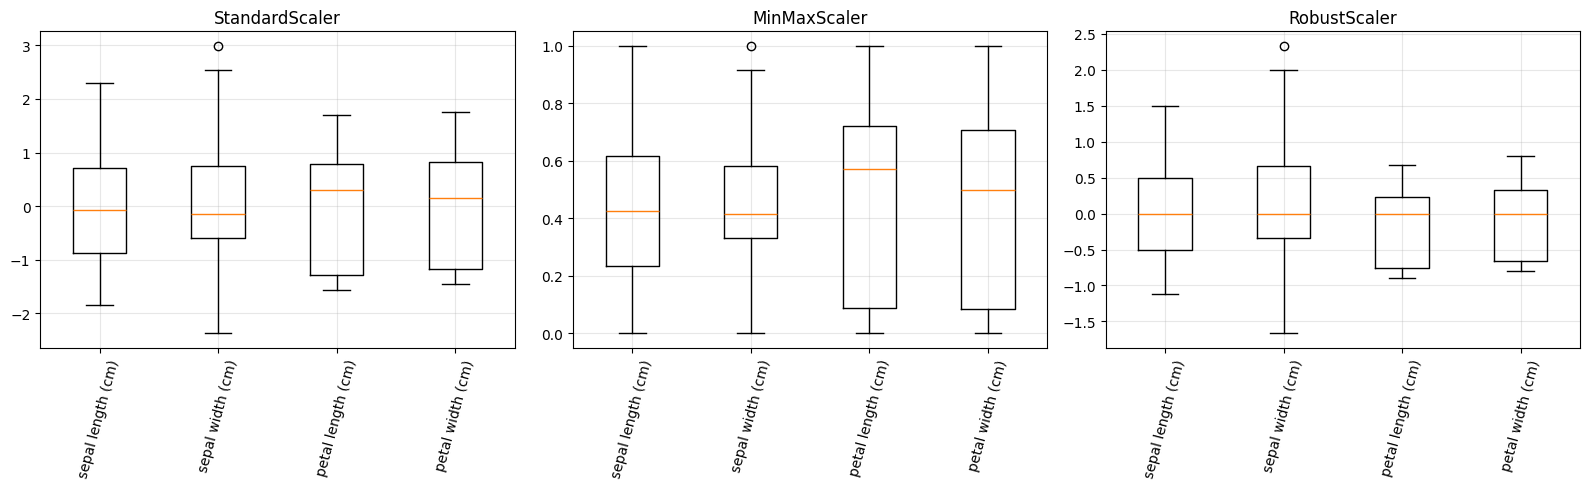

In [5]:
# Cell 5: Compare the transformed training data

scaling_results = {
    "StandardScaler": X_train_standard,
    "MinMaxScaler": X_train_minmax,
    "RobustScaler": X_train_robust
}

for name, values in scaling_results.items():
    print(f"\n{name}")
    print("Mean:", np.round(values.mean(axis=0), 3))
    print("Std:", np.round(values.std(axis=0), 3))
    print("Minimum:", np.round(values.min(axis=0), 3))
    print("Maximum:", np.round(values.max(axis=0), 3))

# Cell 6: Visual comparison

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, values) in zip(axes, scaling_results.items()):
    ax.boxplot(values, tick_labels=X.columns)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=75)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
